# Opgave 1

## 1A

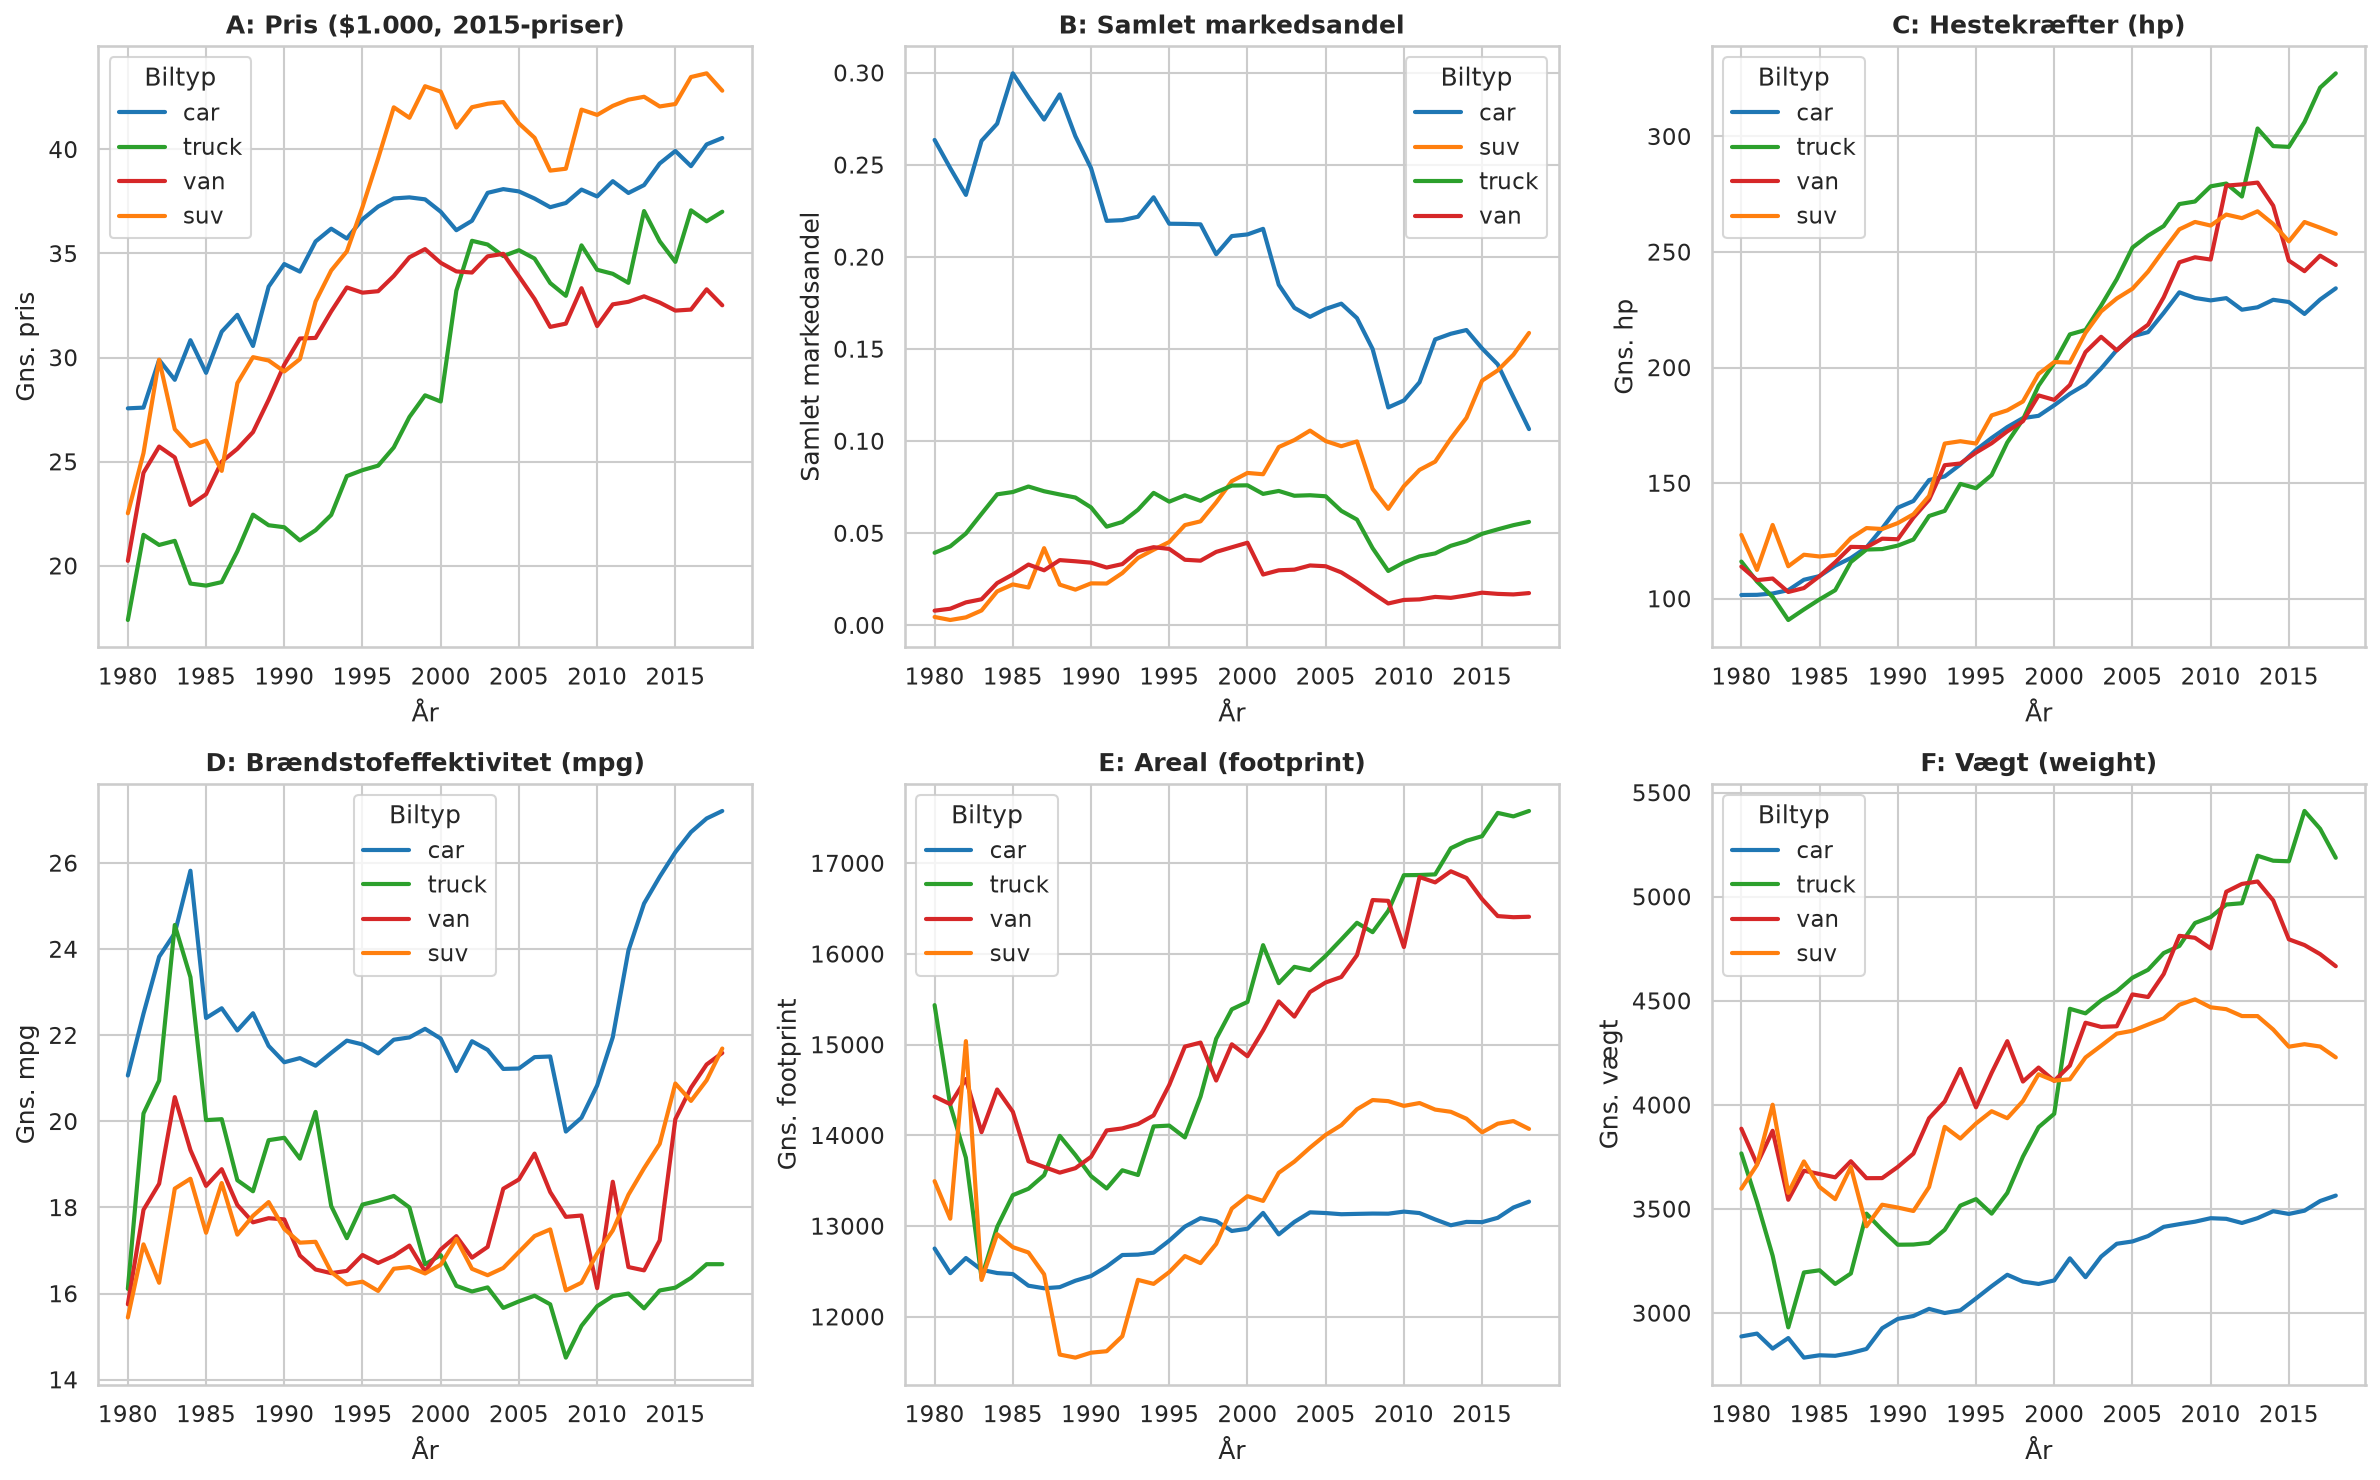

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cars.csv')

type_cols = ['car', 'suv', 'truck', 'van']

def get_body_type(row):
    for c in type_cols:
        if row[c] == 1:
            return c
    return 'other'

df['body_type'] = df.apply(get_body_type, axis=1)

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

palette = {'car': '#1f77b4', 'suv': '#ff7f0e', 'truck': '#2ca02c', 'van': '#d62728'}

sns.lineplot(data=df, x='year', y='price', hue='body_type',
             palette=palette, ax=axes[0, 0], errorbar=None, linewidth=2)
axes[0, 0].set_title('A: Pris ($1.000, 2015-priser)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('År')
axes[0, 0].set_ylabel('Gns. pris')
axes[0, 0].legend(title='Biltyp')

ms_time = df.groupby(['year', 'body_type'])['market_share'].sum().reset_index()
sns.lineplot(data=ms_time, x='year', y='market_share', hue='body_type', palette=palette, ax=axes[0, 1], linewidth=2)
axes[0, 1].set_title('B: Samlet markedsandel', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('År')
axes[0, 1].set_ylabel('Samlet markedsandel')
axes[0, 1].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='hp', hue='body_type',
             palette=palette, ax=axes[0, 2], errorbar=None, linewidth=2)
axes[0, 2].set_title('C: Hestekræfter (hp)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('År')
axes[0, 2].set_ylabel('Gns. hp')
axes[0, 2].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='mpg', hue='body_type',
             palette=palette, ax=axes[1, 0], errorbar=None, linewidth=2)
axes[1, 0].set_title('D: Brændstofeffektivitet (mpg)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('År')
axes[1, 0].set_ylabel('Gns. mpg')
axes[1, 0].legend(title='Biltyp')

# 5. Footprint over time
sns.lineplot(data=df, x='year', y='footprint', hue='body_type',
             palette=palette, ax=axes[1, 1], errorbar=None, linewidth=2)
axes[1, 1].set_title('E: Areal (footprint)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('År')
axes[1, 1].set_ylabel('Gns. footprint')
axes[1, 1].legend(title='Biltyp')

# 6. Weight over time
sns.lineplot(data=df, x='year', y='weight', hue='body_type',
             palette=palette, ax=axes[1, 2], errorbar=None, linewidth=2)
axes[1, 2].set_title('F: Vægt (weight)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('År')
axes[1, 2].set_ylabel('Gns. vægt')
axes[1, 2].legend(title='Biltyp')

plt.tight_layout()
